# 01. Exploración del dataset Adult Income

**Objetivo:** describir la fuente, las variables, los datos ausentes y la distribución de la etiqueta que se intentará predecir. El dataset contiene registros del Censo de Estados Unidos de 1994 y se usa solo con fines académicos.

La clase positiva es ingreso anual superior a 50.000 USD. `fnlwgt` se excluye del modelado porque es un peso censal, no una característica individual para esta tarea. Corre los notebooks en orden desde esta carpeta.


In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from src.utils import cargar_datos

df = cargar_datos()
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Filas duplicadas: {df.duplicated().sum():,}")


Dimensiones: 48,842 filas x 16 columnas
Filas duplicadas: 52


## 1. Muestra y diccionario de variables

La etiqueta `objetivo` vale 1 para ingresos mayores a 50.000 USD y 0 para el resto. `income_raw` conserva la etiqueta original para trazabilidad.


In [2]:
display(df.head())


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income_raw,objetivo
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


In [3]:
diccionario = pd.DataFrame([
    ("age", "Edad en años"),
    ("workclass", "Sector o tipo de empleador"),
    ("fnlwgt", "Peso censal; excluido del modelo"),
    ("education", "Nivel educativo reportado"),
    ("education-num", "Nivel educativo codificado"),
    ("marital-status", "Estado civil"),
    ("occupation", "Ocupación"),
    ("relationship", "Relación familiar en el hogar"),
    ("race", "Categoría racial reportada en la fuente"),
    ("sex", "Sexo según las categorías de la fuente"),
    ("capital-gain", "Ganancia de capital"),
    ("capital-loss", "Pérdida de capital"),
    ("hours-per-week", "Horas trabajadas por semana"),
    ("native-country", "País de origen reportado"),
    ("income_raw", "Etiqueta original de ingresos"),
    ("objetivo", "Etiqueta binaria derivada: 1 si >50K, 0 en otro caso"),
], columns=["Variable", "Descripción"])
display(diccionario)


,Variable,Descripción
0,age,Edad en años
1,workclass,Sector o tipo de empleador
2,fnlwgt,Peso censal; excluido del modelo
3,education,Nivel educativo reportado
4,education-num,Nivel educativo codificado
5,marital-status,Estado civil
6,occupation,Ocupación
7,relationship,Relación familiar en el hogar
8,race,Categoría racial reportada en la fuente
9,sex,Sexo según las categorías de la fuente


## 2. Tipos, estadísticos y datos ausentes

Los valores `?` de la fuente se convierten a ausentes. La imputación se aprende dentro del pipeline, usando solo el conjunto de entrenamiento.


In [4]:
display(df.dtypes.rename("Tipo").to_frame())
resumen_faltantes = pd.DataFrame({
    "Ausentes": df.isna().sum(),
    "Porcentaje": (df.isna().mean() * 100).round(2),
})
display(resumen_faltantes.loc[resumen_faltantes["Ausentes"] > 0].sort_values("Ausentes", ascending=False))
display(df.describe(include="all").T)


,Tipo
age,int64
workclass,str
fnlwgt,int64
education,str
education-num,int64
marital-status,str
occupation,str
relationship,str
race,str
sex,str


,Ausentes,Porcentaje
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,46043,8,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,46033,14,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Distribución de la variable objetivo

La clase >50K es minoritaria. El desbalance hace necesario comparar el modelo con un baseline y revisar recall, precision y F1, además de accuracy.


,Registros,Porcentaje
objetivo,,
<=50K,37155,76.07
>50K,11687,23.93


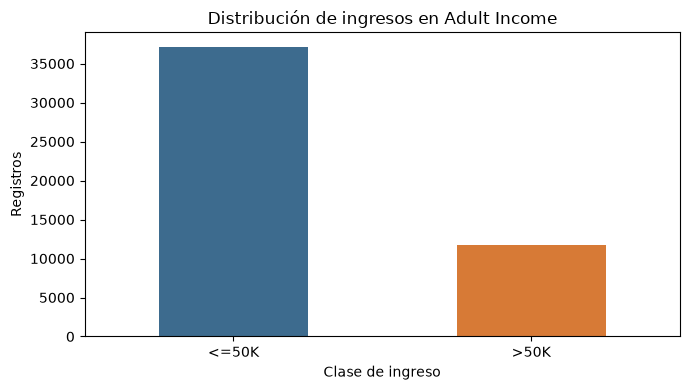

In [5]:
balance = df["objetivo"].value_counts().sort_index().rename(index={0: "<=50K", 1: ">50K"})
balance_tabla = pd.DataFrame({"Registros": balance, "Porcentaje": (balance / len(df) * 100).round(2)})
display(balance_tabla)
ax = balance_tabla["Registros"].plot(kind="bar", color=["#3D6B8E", "#D77A36"], figsize=(7, 4))
ax.set_title("Distribución de ingresos en Adult Income")
ax.set_xlabel("Clase de ingreso")
ax.set_ylabel("Registros")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(ROOT / "data" / "balance_clases.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Exploración de variables

Se muestran distribuciones descriptivas para contextualizar los datos. Estas asociaciones no se interpretan como causas.


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


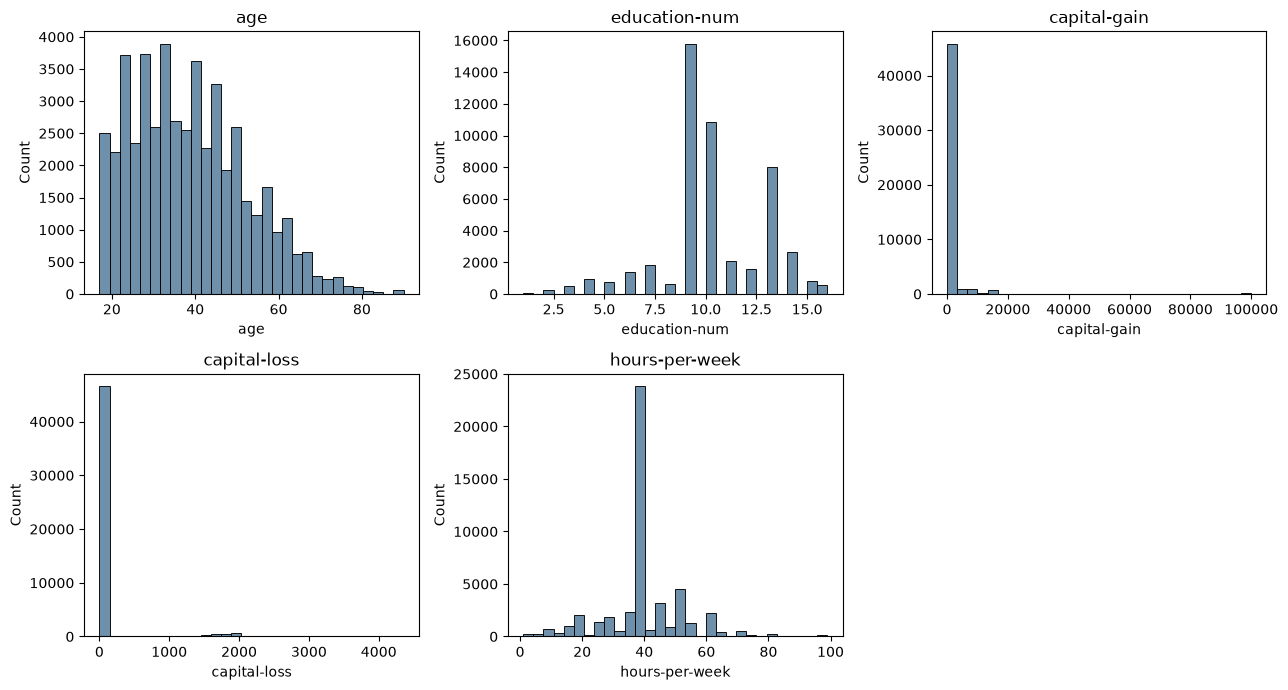

In [6]:
numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
display(df[numericas].describe().T)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, numericas):
    sns.histplot(data=df, x=col, bins=30, ax=ax, color="#3D6B8E")
    ax.set_title(col)
for ax in axes.flat[len(numericas):]:
    ax.remove()
fig.tight_layout()
plt.show()


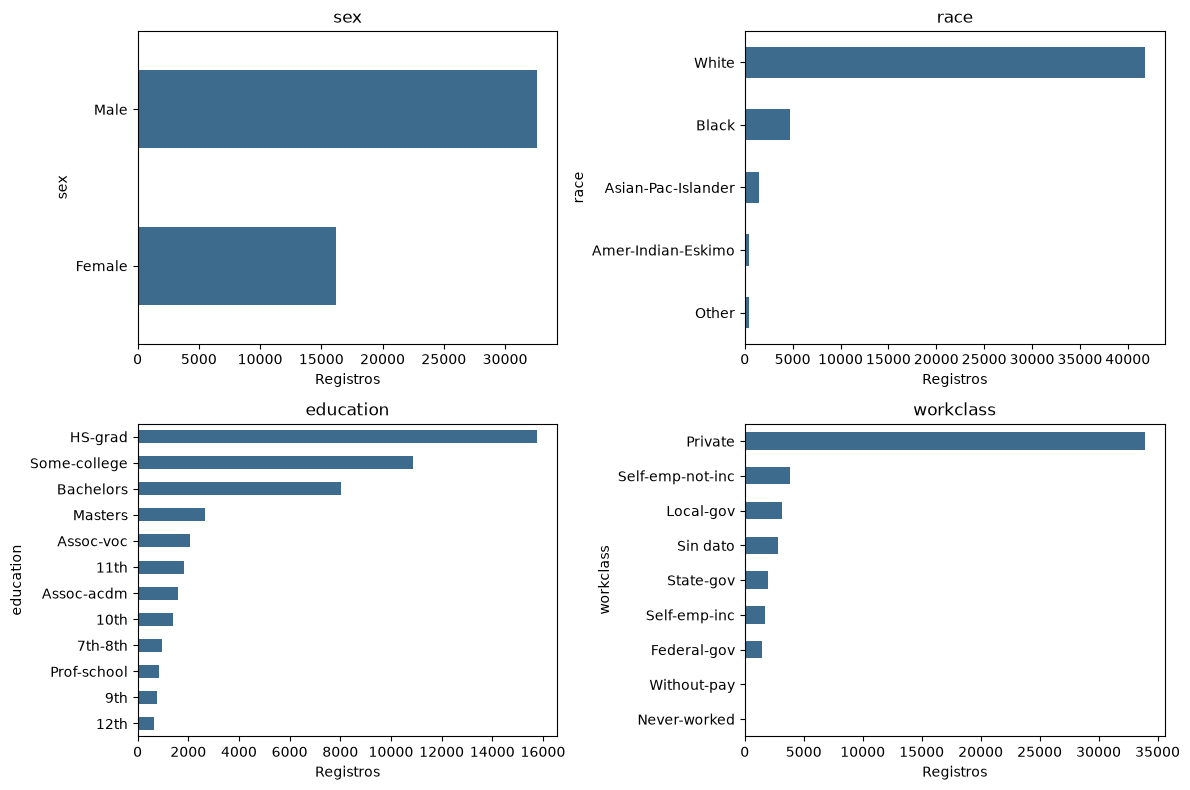

In [7]:
categoricas = ["sex", "race", "education", "workclass"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, categoricas):
    conteos = df[col].fillna("Sin dato").value_counts().head(12)
    conteos.sort_values().plot(kind="barh", ax=ax, color="#3D6B8E")
    ax.set_title(col)
    ax.set_xlabel("Registros")
fig.tight_layout()
plt.show()


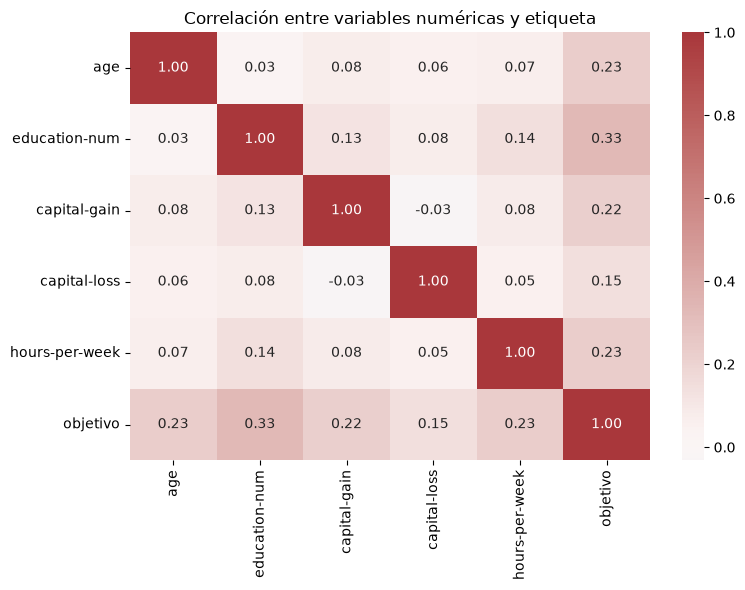

In [8]:
correlacion = df[numericas + ["objetivo"]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlación entre variables numéricas y etiqueta")
fig.tight_layout()
plt.savefig(ROOT / "data" / "correlacion.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Cierre de la exploración

El dataset tiene variables numéricas y categóricas, valores faltantes y una clase positiva minoritaria. El siguiente notebook usa una división estratificada 80/20 y ajusta imputación, escalado y codificación dentro de cada pipeline para no filtrar información del test.
